# **실습 개요**

여러분은 스마트 팩토리의 **설비 예지보전(Predictive Maintenance)** 팀에 합류한 데이터 분석가입니다. <br>
공장의 회전 설비(모터/펌프)에는 진동, 온도, 전류/전압, 압력 등을 측정하는 센서 25개가 부착되어 있고, <br>
이 센서 데이터를 바탕으로 설비 상태(정상 / 주의 / 고장)를 미리 예측해 고장 전에 정비 계획을 세우려고 합니다.

다만 센서 수가 많고, 물리적으로 서로 얽혀 있는 센서들(예: 진동을 측정하는 여러 센서, 온도를 측정하는 여러 센서)이 <br>
강한 상관관계(다중공선성)를 갖고 있어 어떻게 전처리하느냐에 따라 모델 성능이 크게 달라집니다.

## **데이터셋 설명**

설비 1,000대(대수가 아니라 측정 시점 기준)에서 수집한 센서 데이터와 실제 설비 상태(정답)를 담은 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| vibration_x / vibration_y / vibration_z / vibration_axial | 진동 센서 (X/Y/Z축, 축방향, mm/s) |
| noise_level | 설비 소음 레벨 (dB) |
| temp_bearing_1 / temp_bearing_2 | 베어링 온도 (℃) |
| temp_motor | 모터 온도 (℃) |
| temp_gearbox | 기어박스 온도 (℃) |
| temp_housing | 하우징 온도 (℃) |
| current_phase_a / current_phase_b / current_phase_c | 3상 전류 (A) |
| voltage_a / voltage_b / voltage_c | 3상 전압 (V) |
| pressure_inlet / pressure_outlet / pressure_mid | 유입 / 유출 / 중간 압력 (bar) |
| rotation_speed | 회전 속도 (RPM) |
| humidity | 설비 주변 습도 (%) |
| operating_hours | 누적 가동 시간 (시간) |
| oil_quality_index | 윤활유 품질 지수 (0~100, 높을수록 양호) |
| equipment_age_years | 설비 사용 연수 (년) |
| outdoor_installed | 실외 설치 여부 (Yes/No) |
| status | **[target]** 설비 상태 (Normal / Warning / Failure) |

## **데이터셋 URL**
https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/machine_status.csv

## **1. 데이터 살펴보기**

**Q1. 데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.**

In [152]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/machine_status.csv")
df.head()

,vibration_x,vibration_y,vibration_z,vibration_axial,noise_level,temp_bearing_1,temp_bearing_2,temp_motor,temp_gearbox,temp_housing,...,pressure_inlet,pressure_outlet,pressure_mid,rotation_speed,humidity,operating_hours,oil_quality_index,equipment_age_years,outdoor_installed,status
0,7.123,6.652,6.929,6.496,7.026,70.01,63.38,67.00,60.78,64.56,...,4.734,4.480,4.674,1385.0,59.8,3019.8,90.45,13.98,Yes,Warning
1,5.896,5.402,5.410,5.547,5.955,69.37,63.55,67.57,68.94,67.28,...,4.606,4.282,4.404,1570.6,50.0,2210.2,72.00,0.58,No,Warning
2,5.467,4.831,4.879,5.387,5.392,77.81,72.99,73.75,68.76,73.36,...,4.709,4.470,4.885,1445.5,50.0,5447.8,96.38,10.47,Yes,Normal
3,4.963,5.303,5.796,5.451,4.637,77.10,72.35,70.66,75.30,76.93,...,4.932,4.641,4.718,1719.3,62.1,5209.7,80.67,12.65,No,Warning
4,5.469,5.368,5.637,5.929,5.157,71.02,75.60,73.67,78.90,71.75,...,4.677,4.461,4.266,1502.8,47.2,4959.9,87.11,10.76,No,Normal


**Q2. 데이터의 크기와 컬럼별 정보를 확인합니다.**

In [153]:
# code here
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1022 entries, 0 to 1021
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   vibration_x          1022 non-null   float64
 1   vibration_y          1022 non-null   float64
 2   vibration_z          1022 non-null   float64
 3   vibration_axial      1022 non-null   float64
 4   noise_level          1022 non-null   float64
 5   temp_bearing_1       1022 non-null   float64
 6   temp_bearing_2       982 non-null    float64
 7   temp_motor           1022 non-null   float64
 8   temp_gearbox         1022 non-null   float64
 9   temp_housing         1022 non-null   float64
 10  current_phase_a      1022 non-null   float64
 11  current_phase_b      992 non-null    float64
 12  current_phase_c      1022 non-null   float64
 13  voltage_a            1022 non-null   float64
 14  voltage_b            1022 non-null   float64
 15  voltage_c            1022 non-null   float64
 16 

**Q3. 수치형 컬럼들의 기술 통계량을 확인합니다.**

In [154]:
# code here
df.describe()

,vibration_x,vibration_y,vibration_z,vibration_axial,noise_level,temp_bearing_1,temp_bearing_2,temp_motor,temp_gearbox,temp_housing,...,voltage_b,voltage_c,pressure_inlet,pressure_outlet,pressure_mid,rotation_speed,humidity,operating_hours,oil_quality_index,equipment_age_years
count,1022.000000,1022.000000,1022.000000,1022.000000,1022.000000,1022.000000,982.000000,1022.000000,1022.000000,1022.000000,...,1022.000000,1022.000000,1022.000000,1022.000000,1022.000000,1022.000000,970.000000,1022.000000,996.000000,1022.000000
mean,6.473698,6.480381,7.091297,6.444840,6.492987,67.644599,67.628289,67.445910,67.665264,67.536145,...,21.961586,22.036116,4.600812,4.590687,4.603582,1477.069374,45.285979,3683.757436,84.775954,7.754961
std,1.015323,1.027228,4.750587,1.001625,1.034642,4.944803,4.991179,4.826289,4.783194,4.851461,...,9.823294,1.336552,0.303574,0.298983,0.305891,121.874571,10.366099,2811.911009,11.632900,4.198373
min,3.924000,3.814000,3.962000,3.861000,3.587000,53.450000,54.290000,55.410000,54.530000,54.550000,...,-78.078216,18.863000,3.620000,3.635000,3.703000,1086.000000,16.000000,161.100000,50.640000,0.500000
25%,5.696500,5.712000,5.712000,5.691500,5.739250,63.682500,63.845000,63.712500,64.042500,63.675000,...,20.962500,20.997250,4.384250,4.372250,4.382250,1397.250000,38.525000,1600.725000,76.212500,4.092500
50%,6.477500,6.486000,6.478000,6.470000,6.477500,67.720000,67.590000,67.480000,67.650000,67.500000,...,22.108500,22.033000,4.601500,4.586500,4.595000,1471.550000,45.300000,2860.550000,84.155000,7.825000
75%,7.259000,7.213500,7.296750,7.152250,7.282500,71.560000,71.522500,71.275000,71.225000,71.307500,...,23.102250,23.126750,4.813750,4.814250,4.821500,1566.550000,52.600000,5043.600000,93.147500,11.347500
max,9.248000,9.668000,49.943996,9.553000,9.121000,79.430000,82.130000,79.610000,80.280000,78.370000,...,120.922740,25.209000,5.466000,5.377000,5.587000,1913.100000,80.100000,22678.500000,117.020000,14.980000


## **2. 데이터 전처리하기**

### **2-1. 중복 데이터 제거하기**

**Q1. 중복된 행이 몇 개 있는지 확인하세요.**

In [155]:
# code here
df.duplicated().sum()

np.int64(22)

**Q2. 중복된 행을 제거하세요.**

In [156]:
# code here
df = df.drop_duplicates()

In [157]:
df["status"].value_counts()

status
Warning    508
Normal     338
Failure    154
Name: count, dtype: int64

### **2-2. 데이터 분리하기**

**Q1. status를 target으로 하여 train과 test 데이터를 분리하세요.**
- 비율: 7(학습):3(테스트)
- random_state = 101
- status 클래스 비율이 불균형하므로 stratify 옵션을 사용합니다.

In [158]:
# code here
X = df.drop("status", axis = 1)
y = df["status"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify= y, random_state=101)

### **2-3. 결측치 처리하기**

**Q1. train 데이터의 컬럼별 결측치 개수를 확인하세요.**

In [159]:
# code here
X_train.isnull().sum()

vibration_x             0
vibration_y             0
vibration_z             0
vibration_axial         0
noise_level             0
temp_bearing_1          0
temp_bearing_2         23
temp_motor              0
temp_gearbox            0
temp_housing            0
current_phase_a         0
current_phase_b        26
current_phase_c         0
voltage_a               0
voltage_b               0
voltage_c               0
pressure_inlet          0
pressure_outlet         0
pressure_mid            0
rotation_speed          0
humidity               36
operating_hours         0
oil_quality_index      16
equipment_age_years     0
outdoor_installed      13
dtype: int64

**Q2. 결측치가 존재하는 행들의 type을 확인하세요.**

In [160]:
X_train.columns[X_train.isnull().sum() > 0]

Index(['temp_bearing_2', 'current_phase_b', 'humidity', 'oil_quality_index',
       'outdoor_installed'],
      dtype='str')

In [161]:
X_train[X_train.columns[X_train.isnull().sum() > 0]].dtypes

temp_bearing_2       float64
current_phase_b      float64
humidity             float64
oil_quality_index    float64
outdoor_installed        str
dtype: object

**Q3. 수치형 컬럼의 결측치들을 중앙값(median)으로 대체합니다.**

반드시 train 데이터의 통계량으로 test 데이터도 함께 처리해야 데이터 누수(data leakage)를 방지할 수 있습니다.

In [162]:
# code here
fill_cols_num = X_train[X_train.columns[X_train.isnull().sum() > 0]].select_dtypes(include = "number")
fill_cols_num

for c in fill_cols_num:
    fill_vals = X_train[c].median()
    X_train[c] = X_train[c].fillna(fill_vals)
    X_test[c] = X_test[c].fillna(fill_vals)

**Q3. 범주형 컬럼의 결측치를 train 데이터의 최빈값(mode)으로 대체하세요.**

In [163]:
# code here
fill_cols_str = X_train[X_train.columns[X_train.isnull().sum() > 0]].select_dtypes(include = "str")
fill_cols_str

for c in fill_cols_str:
    fill_vals = X_train[c].mode()[0]
    X_train[c] = X_train[c].fillna(fill_vals)
    X_test[c] = X_test[c].fillna(fill_vals)

### **2-4. 이상치 처리하기**

**Q1. IQR을 활용하여 각 수치형 컬럼에 이상치가 몇 개씩 있는지 확인하는 함수를 작성하세요.**

In [164]:
numeric_cols = X_train.select_dtypes(include = "number")

In [165]:
# code here
def find_whisker(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    iqr = Q3 - Q1
    lower = Q1 - 1.5 * iqr
    upper = Q3 + 1.5 * iqr
    return (lower, upper)

In [166]:
d = {}
for c in numeric_cols:
    lower, upper = find_whisker(X_train, c)
    d[c] = (lower, upper)
    outliers = ((X_train[c] < lower) | (X_train[c] > upper)).sum()
    print(f"{c}: {outliers}")
    

vibration_x: 0
vibration_y: 1
vibration_z: 16
vibration_axial: 0
noise_level: 0
temp_bearing_1: 0
temp_bearing_2: 0
temp_motor: 0
temp_gearbox: 0
temp_housing: 0
current_phase_a: 0
current_phase_b: 0
current_phase_c: 0
voltage_a: 0
voltage_b: 11
voltage_c: 0
pressure_inlet: 3
pressure_outlet: 1
pressure_mid: 2
rotation_speed: 5
humidity: 14
operating_hours: 27
oil_quality_index: 4
equipment_age_years: 0


**Q2. 이상치에 해당하는 값들을 모두 clipping 해주세요.**


In [167]:
# code here
for c in numeric_cols:
    lower, upper = d[c]
    X_train[c] = X_train[c].clip(lower, upper)
    X_test[c] = X_test[c].clip(lower, upper)

In [168]:
for c in numeric_cols:
    lower, upper = find_whisker(X_train, c)
    d[c] = (lower, upper)
    outliers = ((X_train[c] < lower) | (X_train[c] > upper)).sum()
    print(f"{c} : {outliers}")

vibration_x : 0
vibration_y : 0
vibration_z : 0
vibration_axial : 0
noise_level : 0
temp_bearing_1 : 0
temp_bearing_2 : 0
temp_motor : 0
temp_gearbox : 0
temp_housing : 0
current_phase_a : 0
current_phase_b : 0
current_phase_c : 0
voltage_a : 0
voltage_b : 0
voltage_c : 0
pressure_inlet : 0
pressure_outlet : 0
pressure_mid : 0
rotation_speed : 0
humidity : 0
operating_hours : 0
oil_quality_index : 0
equipment_age_years : 0


### **2-5. Feature Encoding**

**Q1. outdoor_installed 컬럼을 label 인코딩하세요.**

In [169]:
# code here
X_train["outdoor_installed"] = X_train["outdoor_installed"].map({"Yes" : 1, "No": 0})

In [170]:
X_test["outdoor_installed"] = X_test["outdoor_installed"].map({"Yes" : 1, "No": 0})

### **2-6. 다중공선성 확인하기**

**Q1. train 데이터(수치형 컬럼)의 상관행렬을 시각화하세요.**

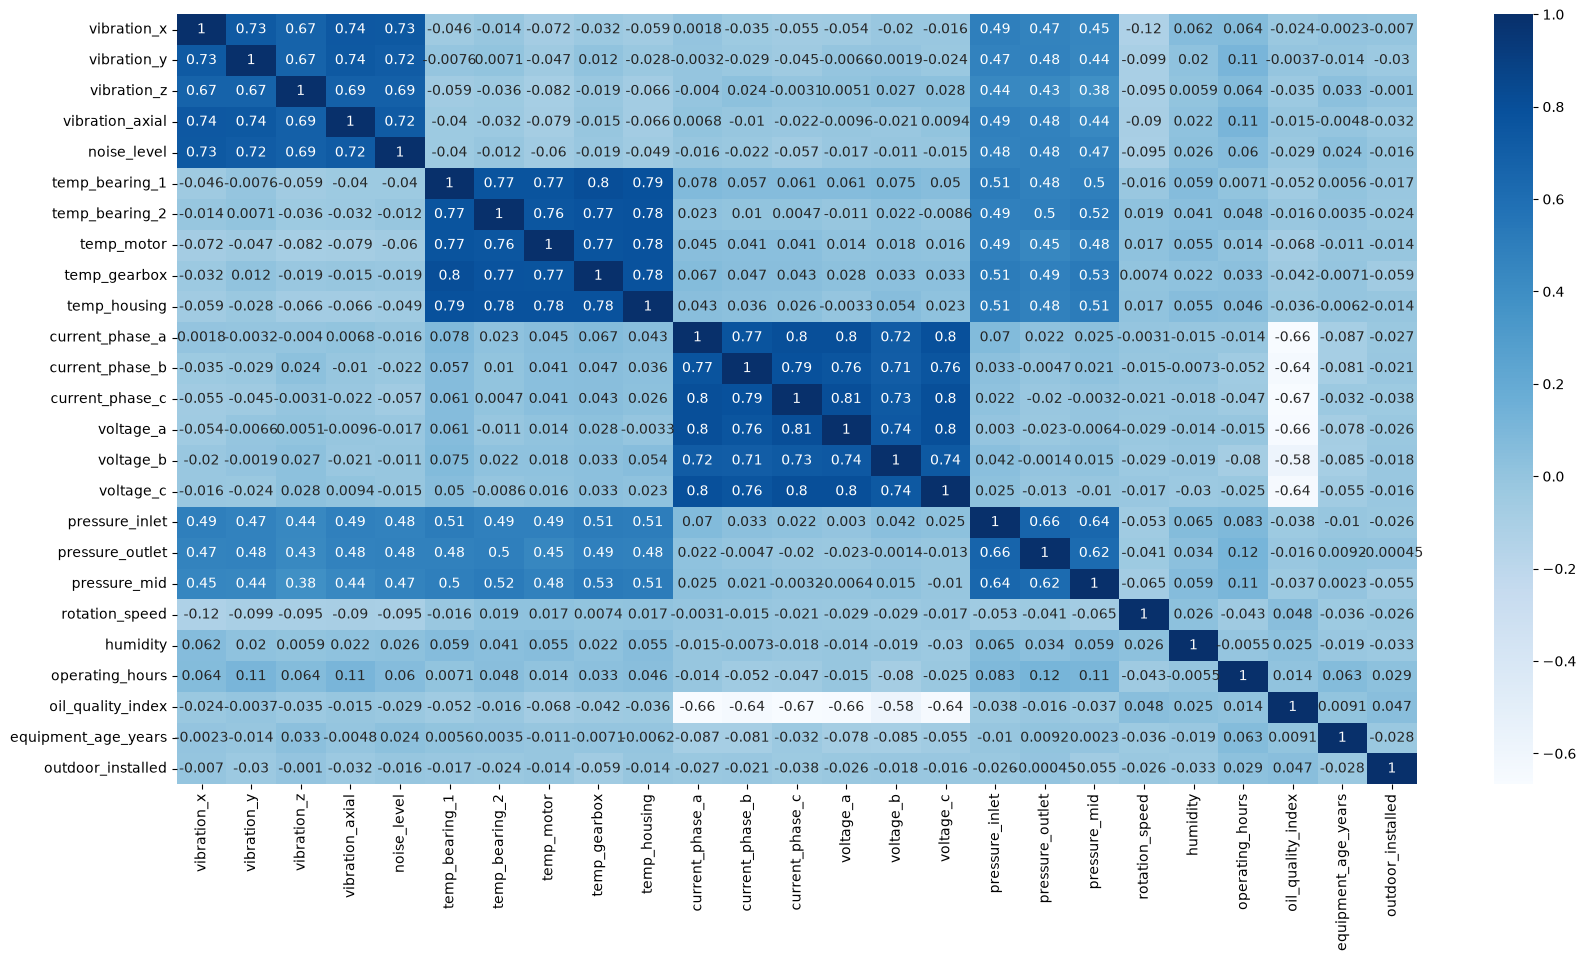

In [171]:
# code here
plt.figure(figsize=(20, 10))
sns.heatmap(X_train.corr(), annot = True, cmap="Blues")
plt.show()

## **다중 공선성 확인하기**

In [172]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant # 한 열에 다 1점부터 시작

# 데이터에 기준점을 하나 추가 -> 학습할 때 추가되면 안됨.
X_vif =add_constant(X_train) # X_train이라는 dataframe에 constant라는 1로만 구성되어 있는 열을 하나 추가
X_vif.head()

,const,vibration_x,vibration_y,vibration_z,vibration_axial,noise_level,temp_bearing_1,temp_bearing_2,temp_motor,temp_gearbox,...,voltage_c,pressure_inlet,pressure_outlet,pressure_mid,rotation_speed,humidity,operating_hours,oil_quality_index,equipment_age_years,outdoor_installed
812,1.0,7.338,7.835,6.853,5.952,7.739,61.45,74.42,63.77,64.46,...,21.098,4.759,4.866,4.752,1437.6,52.8,3459.80,104.56,7.78,1
695,1.0,5.715,6.275,6.760,6.460,6.184,65.46,63.96,66.59,63.17,...,19.933,4.440,4.678,4.305,1512.6,46.0,1417.90,88.83,3.38,0
838,1.0,6.824,5.440,5.195,5.439,4.623,73.16,66.88,68.78,70.28,...,21.277,4.419,4.680,4.658,1313.9,59.8,1097.10,77.86,5.19,0
82,1.0,7.314,7.804,7.349,7.180,6.743,64.79,62.13,62.15,57.45,...,20.628,4.504,4.539,4.396,1227.1,46.1,8119.30,96.44,0.67,0
551,1.0,6.451,5.943,6.327,6.915,6.398,59.52,67.70,62.30,62.48,...,22.956,4.124,4.024,4.138,1494.3,40.4,10569.75,67.79,9.00,0


In [173]:
X_vif.shape

(700, 26)

In [174]:
# 각각의 열이 빠졌을 때 얼마만큼 결과에 영향을 미치는가
vif = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
# 깔끔한 시각화를 위함
vif_df = pd.DataFrame()
vif_df["feature"] = X_vif.columns
vif_df["VIF"] = vif

vif_df

# VIF 값을 해석하는 방법
# 1: 다중공선성 절대 없다.
# 5 이하인 값들 : 상관관계는 있으나, 다중공선성 자체는 없다고 봐도 무방
# 5 ~ 10 : 다중공선성이 있다
# 10 이상 : 아주 심각한 다중공선성이 존재 ->  이 정보는 반드시 feauture engineering이 필요

,feature,VIF
0,const,1.000000
1,vibration_x,3.342118
2,vibration_y,3.017884
3,vibration_z,2.503316
4,vibration_axial,3.291513
5,noise_level,3.196602
6,temp_bearing_1,4.062953
7,temp_bearing_2,3.613551
8,temp_motor,3.645510
9,temp_gearbox,4.041816


### **2-7. Feature Scaling**

**Q1. StandardScaler를 사용하여 feature scaling을 진행하세요.**

In [175]:
# code here
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


## **3. 모델링**

Dimensionality Reduction 없이 KNN모델을 만들어 결과를 확인해 봅시다.

**Q1. Elbow Method를 활용하여 최적의 K값을 찾아 봅시다.**

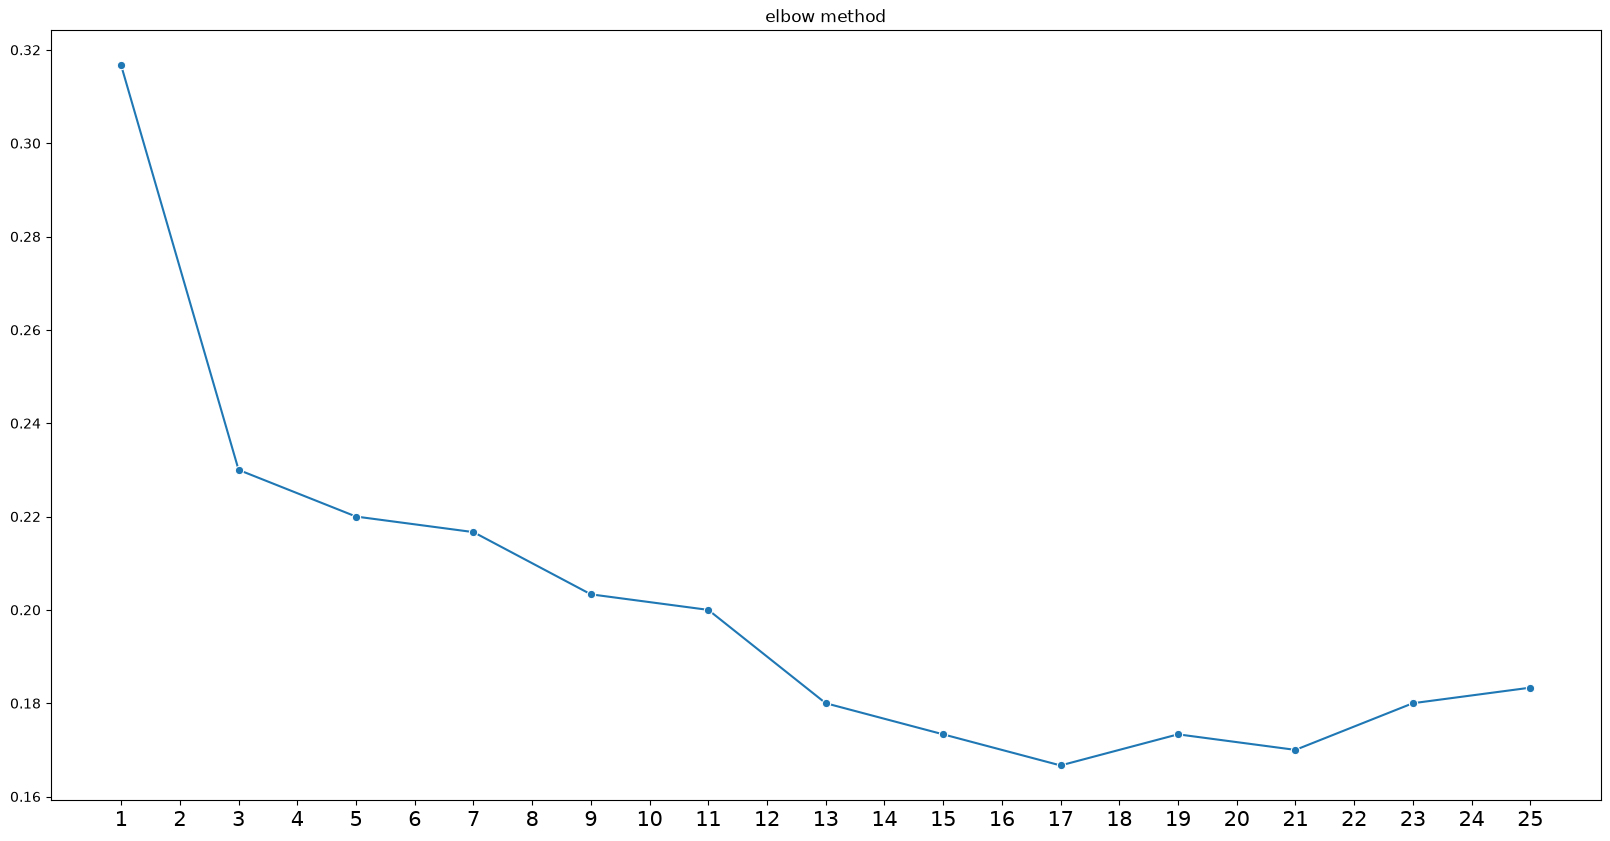

In [176]:
from sklearn.neighbors import KNeighborsClassifier

# 1 ~ n까지 홀수들만 시도
def elbow_method(n):
    errors = []
    for k in range(1, n+1, 2):
        model = KNeighborsClassifier(k)
        model.fit(X_train, y_train)
        # 예측
        y_pred = model.predict(X_test)
        errors.append((y_pred != y_test).mean())


    # 테스트 다 끝난다음, 시각화
    plt.figure(figsize=(20,10))
    plt.title("elbow method")
    sns.lineplot(x = range(1, n+1, 2), y = errors, marker = 'o')
    plt.xticks(range(1, n+1, 1), fontsize = 15)
    plt.show()

elbow_method(25)

In [177]:
# code here
model = KNeighborsClassifier(7)

**Q2. 모델 학습**

최적의 k값을 선택하여 최종 KNN 모델을 학습시키세요.

In [178]:
# code here
model.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",7
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['Failure','Normal','Warning']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


**Q3. 모델 예측**

In [179]:
# code here
y_pred = model.predict(X_test)

**Q4. 모델 평가**

In [ ]:
# code here
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
def evaluate_model(y_true, y_pred):
    print(f"accuray: {accuracy_score(y_test, y_pred)}")
    print(classification_report(y_true, y_pred))
    plt.figure(figsize=(5,3))
    sns.heatmap(confusion_matrix(y_test, y_pred), cmap = "Blues", annot = True)
    plt.show()

accuray: 0.7833333333333333
              precision    recall  f1-score   support

     Failure       0.82      0.72      0.77        46
      Normal       0.78      0.77      0.78       101
     Warning       0.78      0.81      0.79       153

    accuracy                           0.78       300
   macro avg       0.79      0.77      0.78       300
weighted avg       0.78      0.78      0.78       300



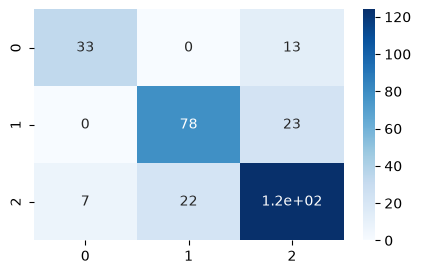

In [181]:
evaluate_model(y_test, y_pred)

## **4. 차원 축소**

**Q1. 주성분 개수를 정하지 않은 상태로 PCA를 학습(fit)합니다.**

In [182]:
# code here
# PCA : 주성분 분석(Principal Component Analysis)
# 비지도 학습, 현재 특징들의 데이터의 손실을 최소화하면서, 더 적은 수의 새로운 특징으로 
# 현재 특징들의 차원을 축소하는 기법이다.
# 주로, 상관관계가 있는 변수들을 하나의 새로운 축으로 변환하는 작업들을 한다.
# 우리의 target에는 관심이 없고, 현재 주어진 특징만을 학습하는 것을 진행.

from sklearn.decomposition import PCA

pca = PCA()
pca.fit(X_train)   # 비지도 학습

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

**Q2. 주성분 비율 시각화 1**

개별 설명분산을 막대 그래프로 그립니다.

In [183]:
# code here
variance_ratio = pca.explained_variance_ratio_
variance_ratio

array([0.23402091, 0.21596606, 0.16593965, 0.04402386, 0.04152415,
       0.03921211, 0.03840518, 0.03651955, 0.01818835, 0.01548183,
       0.01462194, 0.01394082, 0.01314444, 0.01270906, 0.01079997,
       0.01036862, 0.01031522, 0.00966687, 0.00917217, 0.00873853,
       0.00839521, 0.00762002, 0.00740765, 0.00717269, 0.00664511])

**Q3. 주성분 비율 시각화 2**

누적 설명 분산을 선 그래프로 그립니다.

<BarContainer object of 25 artists>

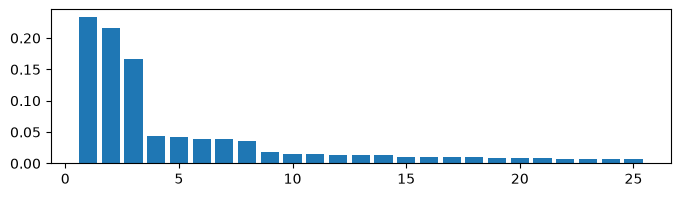

In [184]:
# code here
n = range(1, len(variance_ratio) + 1)

plt.figure(figsize=(8,2))
plt.bar(n, variance_ratio)

**Q3. 주성분 3개로 PCA를 적용하여 train/test 데이터를 변환하세요.**

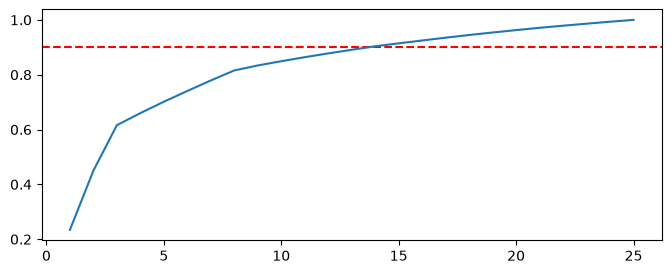

In [185]:
# code here
import numpy as np
cvr = np.cumsum(variance_ratio)
plt.figure(figsize=(8,3))
# x축으로 horizontal한 하나의 선을 그림.
plt.axhline(y = 0.9, color = "red", linestyle = "--")
plt.plot(n, cvr)
plt.show()

**Q4. PC1, PC2를 사용하여 산점도를 그리고, 설비 상태(status)별로 얼마나 잘 구분되는지 확인하세요.**

In [186]:
# code here
pca = PCA(n_components=3)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

In [187]:
X_train_pca

array([[-0.04803783, -2.88501135,  1.29618547],
       [-2.07395265, -1.01015168,  0.30139513],
       [-0.48143445,  0.29809673, -2.00866968],
       ...,
       [ 2.08289342, -1.87033332,  1.15481012],
       [ 0.60480425,  1.48915906, -3.1844516 ],
       [ 2.60612588, -0.87552384,  2.67129176]], shape=(700, 3))

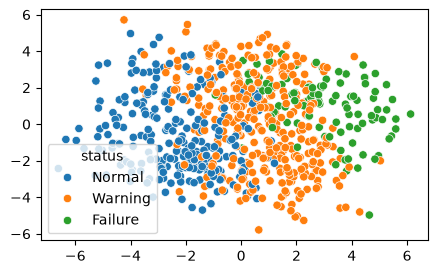

In [188]:
plt.figure(figsize=(5,3))
sns.scatterplot(x = X_train_pca[:,0], y = X_train_pca[:,1], hue = y_train)
plt.show()

## **5. 모델링2**

**Q1. Elbow Method를 활용하여 최적의 K값을 찾아 봅시다.**

단, 이번에는 차원 축소 된 데이터를 활용합니다.

In [189]:
# code here
# 1 ~ n까지 홀수들만 시도
def elbow_method(n):
    errors = []
    for k in range(1, n+1, 2):
        model = KNeighborsClassifier(k)
        model.fit(X_train_pca, y_train)
        # 예측
        y_pred = model.predict(X_test_pca)
        errors.append((y_pred != y_test).mean())


    # 테스트 다 끝난다음, 시각화
    plt.figure(figsize=(20,10))
    plt.title("elbow method")
    sns.lineplot(x = range(1, n+1, 2), y = errors, marker = 'o')
    plt.xticks(range(1, n+1, 1), fontsize = 15)
    plt.show()

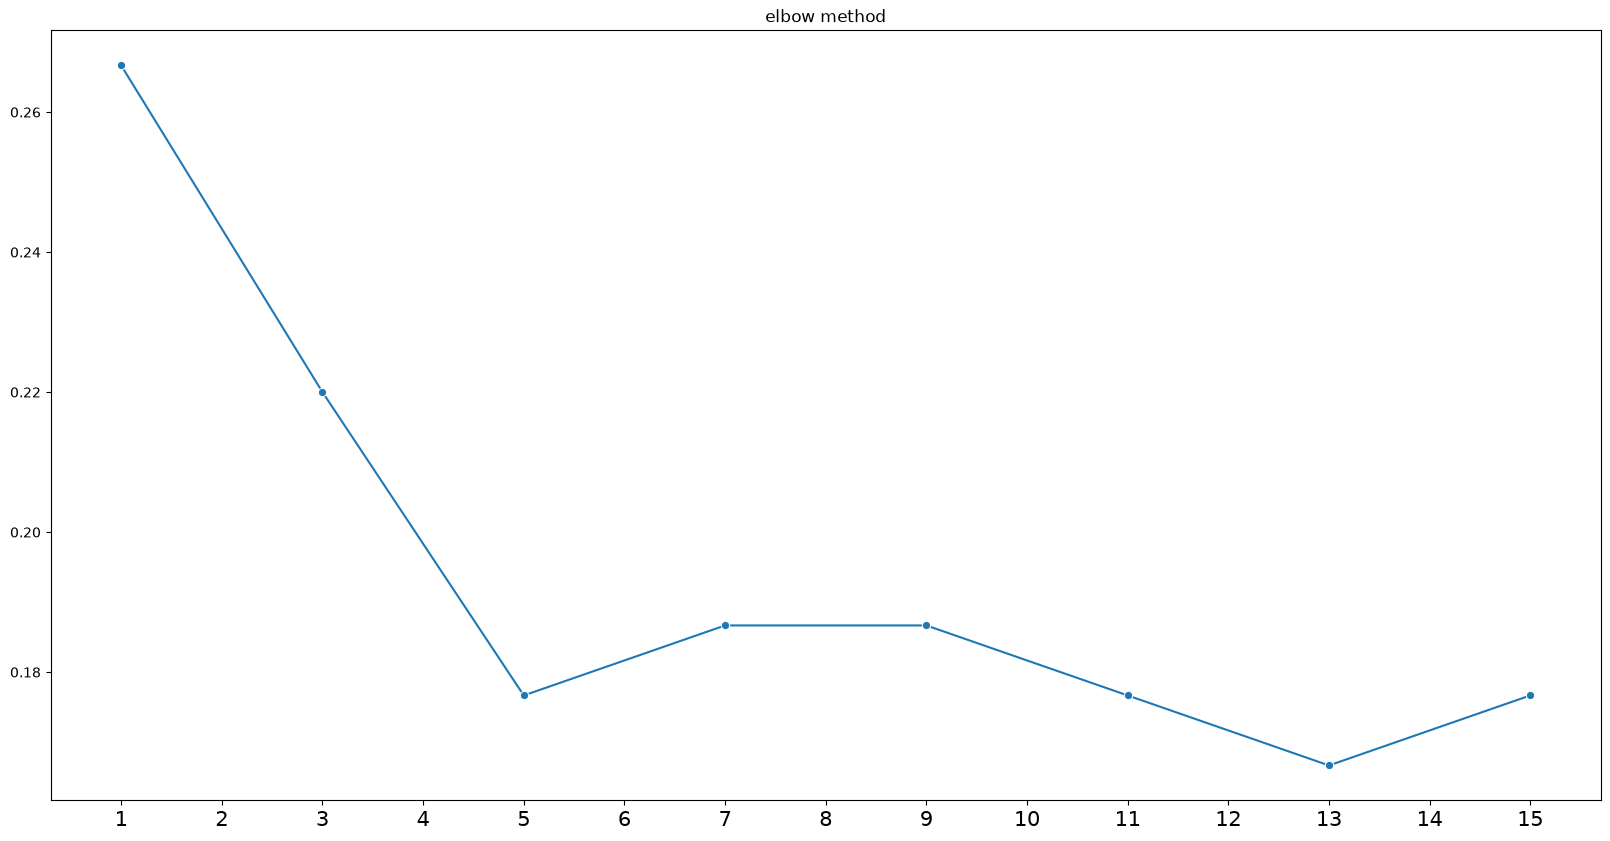

In [190]:
elbow_method(15)

In [191]:
model = KNeighborsClassifier(5)

**Q2. 모델 학습**

최적의 k값을 선택하여 최종 KNN 모델을 학습시키세요.

In [192]:
# code here
model.fit(X_train_pca, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['Failure','Normal','Warning']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


**Q3. 모델 예측**

In [193]:
# code here
y_pred = model.predict(X_test_pca)

In [ ]:
model.

SyntaxError: invalid syntax (1068564517.py, line 1)

**Q4. 모델 평가**

accuray: 0.8233333333333334
              precision    recall  f1-score   support

     Failure       0.80      0.80      0.80        46
      Normal       0.83      0.82      0.83       101
     Warning       0.82      0.83      0.83       153

    accuracy                           0.82       300
   macro avg       0.82      0.82      0.82       300
weighted avg       0.82      0.82      0.82       300



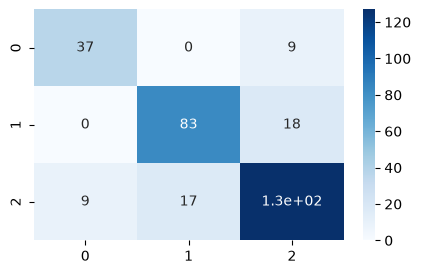

In [194]:
# code here
evaluate_model(y_test, y_pred)

## **6. 제출하기**

데이터 전처리 방법과 학습된 모델을 활용하여 미공개 데이터에 대해 id에 일치하는 예측 결과를 DataFrame의 "status" 컬럼에 기입하고 .csv파일로 저장하여 제출합니다.

**미공개 데이터 URL:**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/machine_status_submission.csv

In [195]:
sub_data = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/machine_status_submission.csv")
sub_data.head()

,id,vibration_x,vibration_y,vibration_z,vibration_axial,noise_level,temp_bearing_1,temp_bearing_2,temp_motor,temp_gearbox,...,voltage_c,pressure_inlet,pressure_outlet,pressure_mid,rotation_speed,humidity,operating_hours,oil_quality_index,equipment_age_years,outdoor_installed
0,1,7.077,6.674,6.977,7.477,7.488,72.80,70.18,70.98,72.83,...,21.758,4.907,4.920,4.484,1386.6,56.0,2812.6,78.66,0.71,No
1,2,8.175,7.318,7.833,8.456,7.654,61.08,64.24,61.72,62.39,...,19.956,4.710,4.710,4.613,1344.0,36.7,2679.5,100.10,9.73,Yes
2,3,6.213,6.169,6.524,6.124,5.735,69.62,67.42,67.26,67.39,...,20.581,4.621,4.723,4.538,1463.5,61.0,1769.7,112.99,0.54,Yes
3,4,7.994,7.896,8.110,7.885,8.409,73.66,68.51,72.16,69.73,...,20.689,4.948,5.098,5.192,1572.9,38.8,11546.6,95.22,13.22,Yes
4,5,5.957,6.715,6.845,6.685,6.889,74.41,74.26,75.36,74.76,...,23.210,4.728,4.977,4.568,1373.0,45.0,2676.2,93.44,0.98,No


In [196]:
numeric_cols_sub = sub_data.select_dtypes(include="number").columns

In [197]:
d_sub = {}
for c in numeric_cols_sub:
    lower, upper = find_whisker(sub_data, c)
    d_sub[c] = (lower, upper)
    outliers = ((sub_data[c] < lower) | (sub_data[c] > upper)).sum()
    print(f"{c}: {outliers}")

id: 0
vibration_x: 0
vibration_y: 0
vibration_z: 0
vibration_axial: 0
noise_level: 1
temp_bearing_1: 0
temp_bearing_2: 0
temp_motor: 0
temp_gearbox: 0
temp_housing: 0
current_phase_a: 0
current_phase_b: 0
current_phase_c: 0
voltage_a: 0
voltage_b: 0
voltage_c: 0
pressure_inlet: 0
pressure_outlet: 0
pressure_mid: 0
rotation_speed: 2
humidity: 2
operating_hours: 6
oil_quality_index: 1
equipment_age_years: 0


In [198]:
for c in numeric_cols_sub:
    lower, upper = d_sub[c]
    sub_data[c] = sub_data[c].clip(lower, upper)

In [199]:
sub_data["outdoor_installed"] = sub_data["outdoor_installed"].map({"Yes" : 1, "No" : 0})

In [200]:
ids = sub_data["id"]

In [201]:
sub_data = sub_data.drop("id", axis = 1)

In [202]:
sub_data_scaled = scaler.transform(sub_data)

In [203]:
sub_data_scaled_pca = pca.transform(sub_data_scaled)

In [204]:
y_pred_sub = model.predict(sub_data_scaled_pca)

In [207]:
y_pred_sub = pd.DataFrame(y_pred_sub, columns=["status"])

In [208]:
pd.concat([ids, y_pred_sub], axis = 1).to_csv("unspervised.csv", index=False)